# **GA4 Ecommerce Funnel and Conversion Analysis**

Use Matplotlib, statsmodels, and Pandas packages to create visualizations and run statistical tests

**Aim:** Using Google Cloud and Python, I want to identify where users drop off in an e-commerce purchase funnel and quantify whether conversion rate differences across device types and traffic sources are statistically meaningful — moving beyond surface-level observation into a defensible, data-driven business recommendation.

**Methodology: Data Acquisition & Setup**

* **Source Selection:** Utilized the [Google Cloud Public Datasets](https://cloud.google.com/datasets) inventory to access verified, production-scale behavioral data.
* **Dataset Identification:** Selected the [GA4 Obfuscated Sample E-commerce dataset](https://console.cloud.google.com/bigquery?ws=!1m4!1m3!3m2!1sbigquery-public-data!2sga4_obfuscated_sample_ecommerce), featuring event-level Google Analytics 4 export data (sessions, product views, cart activity, purchases) from the Google Merchandise Store.
* **Data Pipeline:** Employed the `google-cloud-bigquery` library to execute SQL queries directly against the source — including aggregations across nested STRUCT fields (`traffic_source`, `device`) — extracting targeted samples into Pandas DataFrames for analysis.
* **Statistical Testing:** Leveraged `statsmodels` to run two-proportion z-tests, validating whether observed conversion-rate differences across segments were statistically significant or attributable to random variation.
* **Visualization Engine:** Leveraged the Matplotlib library to transform aggregated funnel and segment data into comparative conversion profiles.

**Connecting to google cloud and importing the BigQuery Dataset**

In [5]:
from google.colab import auth
auth.authenticate_user()

from google.cloud import bigquery
project_id = "project-20c674a6-d84d-4219-be6"
client = bigquery.Client(project=project_id)

In [2]:
query_sample = """
SELECT *
FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_20201105`
LIMIT 20
"""
df_sample = client.query(query_sample).to_dataframe()
df_sample

,event_date,event_timestamp,event_name,event_params,event_previous_timestamp,event_value_in_usd,event_bundle_sequence_id,event_server_timestamp_offset,user_id,user_pseudo_id,...,user_ltv,device,geo,app_info,traffic_source,stream_id,platform,event_dimensions,ecommerce,items
0,20201105,1604610224470219,page_view,"[{'key': 'medium', 'value': {'string_value': '...",<NA>,NaN,-3178299449,<NA>,None,1019538.3425152743,...,"{'revenue': 0.0, 'currency': 'USD'}","{'category': 'desktop', 'mobile_brand_name': '...","{'continent': 'Americas', 'sub_continent': 'No...",None,"{'medium': '(none)', 'name': '(direct)', 'sour...",2100450278,WEB,None,"{'total_item_quantity': None, 'purchase_revenu...",[]
1,20201105,1604610217844791,user_engagement,"[{'key': 'campaign', 'value': {'string_value':...",<NA>,NaN,5878246859,<NA>,None,1019538.3425152743,...,"{'revenue': 0.0, 'currency': 'USD'}","{'category': 'desktop', 'mobile_brand_name': '...","{'continent': 'Americas', 'sub_continent': 'No...",None,"{'medium': '(none)', 'name': '(direct)', 'sour...",2100450278,WEB,None,"{'total_item_quantity': None, 'purchase_revenu...",[]
2,20201105,1604610193148369,session_start,"[{'key': 'page_location', 'value': {'string_va...",<NA>,NaN,-4261873944,<NA>,None,1019538.3425152743,...,"{'revenue': 0.0, 'currency': 'USD'}","{'category': 'desktop', 'mobile_brand_name': '...","{'continent': 'Americas', 'sub_continent': 'No...",None,"{'medium': '(none)', 'name': '(direct)', 'sour...",2100450278,WEB,None,"{'total_item_quantity': None, 'purchase_revenu...",[]
3,20201105,1604610209703652,page_view,"[{'key': 'campaign', 'value': {'string_value':...",<NA>,NaN,3338910232,<NA>,None,1019538.3425152743,...,"{'revenue': 0.0, 'currency': 'USD'}","{'category': 'desktop', 'mobile_brand_name': '...","{'continent': 'Americas', 'sub_continent': 'No...",None,"{'medium': '(none)', 'name': '(direct)', 'sour...",2100450278,WEB,None,"{'total_item_quantity': None, 'purchase_revenu...",[]
4,20201105,1604610193148369,page_view,"[{'key': 'debug_mode', 'value': {'string_value...",<NA>,NaN,-4261873944,<NA>,None,1019538.3425152743,...,"{'revenue': 0.0, 'currency': 'USD'}","{'category': 'desktop', 'mobile_brand_name': '...","{'continent': 'Americas', 'sub_continent': 'No...",None,"{'medium': '(none)', 'name': '(direct)', 'sour...",2100450278,WEB,None,"{'total_item_quantity': None, 'purchase_revenu...",[]
5,20201105,1604610224993603,user_engagement,"[{'key': 'page_title', 'value': {'string_value...",<NA>,NaN,-9882377877,<NA>,None,1019538.3425152743,...,"{'revenue': 0.0, 'currency': 'USD'}","{'category': 'desktop', 'mobile_brand_name': '...","{'continent': 'Americas', 'sub_continent': 'No...",None,"{'medium': '(none)', 'name': '(direct)', 'sour...",2100450278,WEB,None,"{'total_item_quantity': None, 'purchase_revenu...",[]
6,20201105,1604610201890226,user_engagement,"[{'key': 'debug_mode', 'value': {'string_value...",<NA>,NaN,874484958,<NA>,None,1019538.3425152743,...,"{'revenue': 0.0, 'currency': 'USD'}","{'category': 'desktop', 'mobile_brand_name': '...","{'continent': 'Americas', 'sub_continent': 'No...",None,"{'medium': '(none)', 'name': '(direct)', 'sour...",2100450278,WEB,None,"{'total_item_quantity': None, 'purchase_revenu...",[]
7,20201105,1604610193148369,first_visit,"[{'key': 'engaged_session_event', 'value': {'s...",<NA>,NaN,-4261873944,<NA>,None,1019538.3425152743,...,"{'revenue': 0.0, 'currency': 'USD'}","{'category': 'desktop', 'mobile_brand_name': '...","{'continent': 'Americas', 'sub_continent': 'No...",None,"{'medium': '(none)', 'name': '(direct)', 'sour...",2100450278,WEB,None,"{'total_item_quantity': None, 'purchase_revenu...",[]
8,20201105,1604611065751362,session_start,"[{'key': 'page_location', 'value': {'string_va...",<NA>,NaN,-3721097388,<NA>,None,1025449.0583858446,...,"{'revenue': 0.0, 'currency': 'USD'}","{'category': 'desktop', 'mobile_brand_name': '...","{'continent': 'Europe', 'sub_continent': 'Sout...",None,"{'medium': 'organic', 'name': '(organic)', 'so...",2100450278,WEB,

The GA4 export schema is event-level, not row-per-session. Every single thing a user does (viewing a page, adding to cart, purchasing) is one row in an events_YYYYMMDD table — one table per day, which is why queries use wildcards (events_*) and _TABLE_SUFFIX to select date ranges.

**Key fields:**

user_pseudo_id — anonymized user ID

event_name — what happened (session_start, view_item, add_to_cart, purchase, etc.)

event_date — the day

traffic_source — a nested/record field (source, medium, campaign)

device, geo — also nested records with device category, browser, country, city

Because traffic_source, device, and geo are nested STRUCT fields, access their sub-fields with dot notation (traffic_source.source, device.category)

**Explore the funnel: sessions → product views → add to cart → purchase**

Filters the full event stream down to just the 5 funnel-relevant event types, then counts distinct users per event per day.

In [3]:
query = """
SELECT
  event_date,
  event_name,
  COUNT(DISTINCT user_pseudo_id) AS unique_users,
  COUNT(*) AS event_count
FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
WHERE _TABLE_SUFFIX BETWEEN '20201101' AND '20201130'
  AND event_name IN ('session_start', 'view_item', 'add_to_cart', 'begin_checkout', 'purchase')
GROUP BY event_date, event_name
ORDER BY event_date, event_name
"""
df_funnel = client.query(query).to_dataframe()
df_funnel.head(20)

,event_date,event_name,unique_users,event_count
0,20201101,add_to_cart,1,4
1,20201101,begin_checkout,91,127
2,20201101,purchase,13,14
3,20201101,session_start,2339,2594
4,20201101,view_item,516,3380
5,20201102,begin_checkout,127,219
6,20201102,purchase,39,49
7,20201102,session_start,3227,3682
8,20201102,view_item,782,4935
9,20201103,begin_checkout,136,233


**Build the aggregate funnel**

Collapses daily counts into one number per funnel stage for the month, in the correct logical order (session → view → cart → checkout → purchase).

event_name
session_start     92322
view_item         24456
add_to_cart        2122
begin_checkout     4474
purchase           1601
Name: unique_users, dtype: Int64


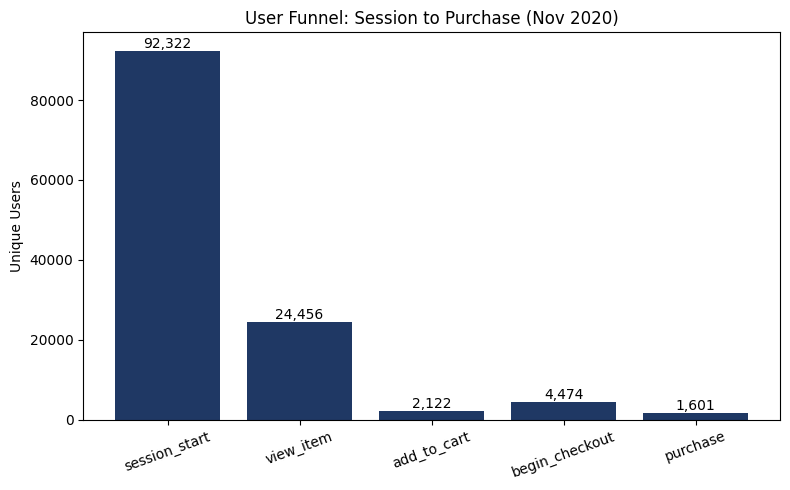

In [3]:
funnel_totals = df_funnel.groupby('event_name')['unique_users'].sum().reindex(
    ['session_start', 'view_item', 'add_to_cart', 'begin_checkout', 'purchase']
)
print(funnel_totals)

import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.bar(funnel_totals.index, funnel_totals.values, color='#1F3864')
plt.title('User Funnel: Session to Purchase (Nov 2020)')
plt.ylabel('Unique Users')
plt.xticks(rotation=20)
for i, v in enumerate(funnel_totals.values):
    plt.text(i, v, f"{v:,}", ha='center', va='bottom')
plt.tight_layout()
plt.savefig('funnel_chart.png', dpi=150)
plt.show()

**Drop-off rate between each stage**

Calculates drop-off between consecutive stages — 1 - (next stage / current stage). This is the actual "so what" of the analysis as raw funnel counts alone don't tell us where the leak is.

In [4]:
import numpy as np
stages = funnel_totals.index.tolist()
values = funnel_totals.values
drop_off = [(1 - values[i+1]/values[i])*100 for i in range(len(values)-1)]
for stage, rate in zip(stages[1:], drop_off):
    print(f"Drop-off before '{stage}': {rate:.1f}%")

Drop-off before 'view_item': 73.5%
Drop-off before 'add_to_cart': 91.3%
Drop-off before 'begin_checkout': -110.8%
Drop-off before 'purchase': 64.2%


The -110.8% "drop-off" before begin_checkout is a red flag in the data, not a real negative drop-off (you can't lose negative users). This happens because our funnel assumes strict sequential flow (every purchaser passed through every prior stage in order), but GA4 event data doesn't actually guarantee that. Users can trigger begin_checkout without a distinct add_to_cart event firing first (e.g., "buy now" flows, or add-to-cart happening in an earlier untracked session). So this is a data limitation.

**Traffic source performance**

Pivots to a different dimension (acquisition channel) instead of time, and computes each channel's own conversion rate.

In [5]:
query2 = """
SELECT
  traffic_source.source AS source,
  COUNT(DISTINCT user_pseudo_id) AS users,
  COUNTIF(event_name = 'purchase') AS purchases
FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
WHERE _TABLE_SUFFIX BETWEEN '20201101' AND '20201130'
GROUP BY source
ORDER BY users DESC
LIMIT 15
"""
df_source = client.query(query2).to_dataframe()
df_source['conversion_rate'] = (df_source['purchases'] / df_source['users'] * 100).round(2)
df_source

,source,users,purchases,conversion_rate
0,google,34388,573,1.67
1,<Other>,26582,494,1.86
2,(direct),22795,438,1.92
3,shop.googlemerchandisestore.com,8448,248,2.94
4,(data deleted),6631,301,4.54


**Comparing conversion-rate difference between top 2 traffic sources**

Testing whether the conversion-rate difference between your top 2 traffic sources is a real effect or just random noise.

In [7]:
from statsmodels.stats.proportion import proportions_ztest

count = df_source.loc[:1, 'purchases'].values
nobs = df_source.loc[:1, 'users'].values
stat, pval = proportions_ztest(count, nobs)
print(f"z-stat: {stat:.3f}, p-value: {pval:.4f}")

z-stat: -1.794, p-value: 0.0728


p-value = 0.0728 means: if there were truly no difference in conversion rate between these two sources, we'd see a gap this large (or larger) about 7.3% of the time just by chance.
At the standard threshold of 0.05: this result does not reach statistical significance — it's close, but you can't confidently say one source converts better than the other. It's a trend, not a proven effect.
The negative z-stat just tells us the direction — the first source in the pair has a lower conversion rate than the second.

**Comparing converstion rates of device_category**

In [8]:
query3 = """
SELECT
  device.category AS device_category,
  COUNT(DISTINCT user_pseudo_id) AS users,
  COUNTIF(event_name = 'purchase') AS purchases
FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
WHERE _TABLE_SUFFIX BETWEEN '20201101' AND '20201130'
GROUP BY device_category
"""
df_device = client.query(query3).to_dataframe()
df_device['conversion_rate'] = (df_device['purchases'] / df_device['users'] * 100).round(2)

In [10]:
df_device

,device_category,users,purchases,conversion_rate
0,mobile,31824,872,2.74
1,desktop,46310,1144,2.47
2,tablet,1789,38,2.12


This is a real, usable finding: mobile actually converts better than desktop here — which is somewhat counter to the common assumption that mobile underperforms. That's a good "surprising insight".
Desktop has by far the most volume (46K users vs 32K mobile), so even at a slightly lower conversion rate, it's likely still the largest absolute revenue driver — worth noting both dimensions (rate vs. volume) rather than just rate alone.
Tablet is a small, low-converting segment — not much strategic weight given its tiny user base (1,789 vs tens of thousands elsewhere).

In [19]:
query4 = """
SELECT
  FORMAT_DATE('%A', PARSE_DATE('%Y%m%d', event_date)) AS day_of_week,
  COUNTIF(event_name = 'purchase') AS purchases
FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
WHERE _TABLE_SUFFIX BETWEEN '20201101' AND '20201130'
GROUP BY day_of_week
ORDER BY purchases DESC
"""

In [20]:
df_dow = client.query(query4).to_dataframe()
df_dow

,day_of_week,purchases
0,Monday,452
1,Tuesday,358
2,Friday,352
3,Wednesday,286
4,Thursday,221
5,Saturday,207
6,Sunday,178


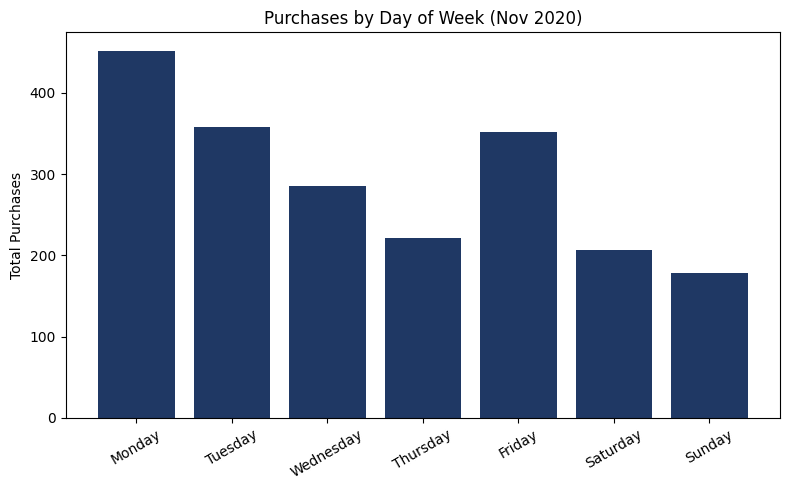

In [23]:
plt.figure(figsize=(8,5))
plt.bar(df_dow['day_of_week'], df_dow['purchases'], color='#1F3864')
plt.title('Purchases by Day of Week (Nov 2020)')
plt.ylabel('Total Purchases')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('dow_chart.png', dpi=150)
plt.show()

Weekday-skewed, not weekend-skewed — matches common B2B/desk-worker shopping behavior (people browse/buy during the work week, not weekends)

In [24]:
query4b = """
SELECT
  FORMAT_DATE('%A', PARSE_DATE('%Y%m%d', event_date)) AS day_of_week,
  COUNT(DISTINCT user_pseudo_id) AS users,
  COUNTIF(event_name = 'purchase') AS purchases
FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
WHERE _TABLE_SUFFIX BETWEEN '20201101' AND '20201130'
GROUP BY day_of_week
"""
df_dow2 = client.query(query4b).to_dataframe()
df_dow2['day_of_week'] = pd.Categorical(df_dow2['day_of_week'], categories=day_order, ordered=True)
df_dow2 = df_dow2.sort_values('day_of_week')
df_dow2['conversion_rate'] = (df_dow2['purchases'] / df_dow2['users'] * 100).round(2)
df_dow2

,day_of_week,users,purchases,conversion_rate
2,Monday,16154,452,2.8
6,Tuesday,14842,358,2.41
1,Wednesday,14222,286,2.01
3,Thursday,13359,221,1.65
5,Friday,12430,352,2.83
0,Saturday,9720,207,2.13
4,Sunday,11340,178,1.57


Monday: 2.8% conversion — highest, and also decent volume
Friday: 2.83% — actually edges out Monday once normalized, despite lower raw purchase count (352 vs 452), because Friday also has fewer total users (12,430 vs 16,154)
Tuesday: drops to 2.41% despite being 2nd in raw purchases — meaning Tuesday's high raw number was partly just a volume effect, not a real efficiency edge
Sunday: lowest both in volume and rate (1.57%) — the weakest day on every measure

Testing whether the conversion-rate difference between Mobile and Desktop is a real effect or just random noise.

In [11]:
subset = df_device[df_device['device_category'].isin(['mobile', 'desktop'])]
count = subset['purchases'].values
nobs = subset['users'].values
stat, pval = proportions_ztest(count, nobs)
print(f"z-stat: {stat:.3f}, p-value: {pval:.4f}")

z-stat: 2.337, p-value: 0.0194


p-value = 0.0194 — this is below the 0.05 threshold, so this result is statistically significant. The conversion-rate gap between mobile (2.74%) and desktop (2.47%) is very unlikely to be due to chance alone — there's less than a 2% probability we'd see a gap this large if there were truly no real difference between the two.

z-stat = 2.337 — positive this time (assuming you ran mobile first), meaning mobile's conversion rate is meaningfully higher than desktop's.

Why is ths a stronger result than your traffic-source test?
the sample sizes here are much larger (31,824 mobile users vs. 46,310 desktop users, compared to the top 2 traffic sources) — larger samples give a test more statistical power to detect real differences, which is part of why this one crossed the significance threshold and the traffic-source one didn't quite.

In [15]:
query5 = """
SELECT
  traffic_source.source AS source,
  device.category AS device_category,
  COUNT(DISTINCT user_pseudo_id) AS users,
  COUNTIF(event_name = 'purchase') AS purchases
FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
WHERE _TABLE_SUFFIX BETWEEN '20201101' AND '20201130'
  AND device.category IN ('mobile', 'desktop')
GROUP BY source, device_category
HAVING users >= 200
ORDER BY source, device_category
"""
df_cross = client.query(query5).to_dataframe()
df_cross['conversion_rate'] = (df_cross['purchases'] / df_cross['users'] * 100).round(2)
df_cross

,source,device_category,users,purchases,conversion_rate
0,(data deleted),desktop,3821,178,4.66
1,(data deleted),mobile,2687,118,4.39
2,(direct),desktop,13275,252,1.9
3,(direct),mobile,9115,178,1.95
4,<Other>,desktop,15484,280,1.81
5,<Other>,mobile,10551,206,1.95
6,google,desktop,19957,294,1.47
7,google,mobile,13730,272,1.98
8,shop.googlemerchandisestore.com,desktop,4903,140,2.86
9,shop.googlemerchandisestore.com,mobile,3378,98,2.9


In [16]:
pivot = df_cross.pivot(index='source', columns='device_category', values='conversion_rate')
pivot['mobile_advantage'] = pivot['mobile'] - pivot['desktop']
pivot.sort_values('mobile_advantage', ascending=False)

device_category,desktop,mobile,mobile_advantage
source,,,
google,1.47,1.98,0.51
<Other>,1.81,1.95,0.14
(direct),1.9,1.95,0.05
shop.googlemerchandisestore.com,2.86,2.9,0.04
(data deleted),4.66,4.39,-0.27


<Figure size 900x500 with 0 Axes>

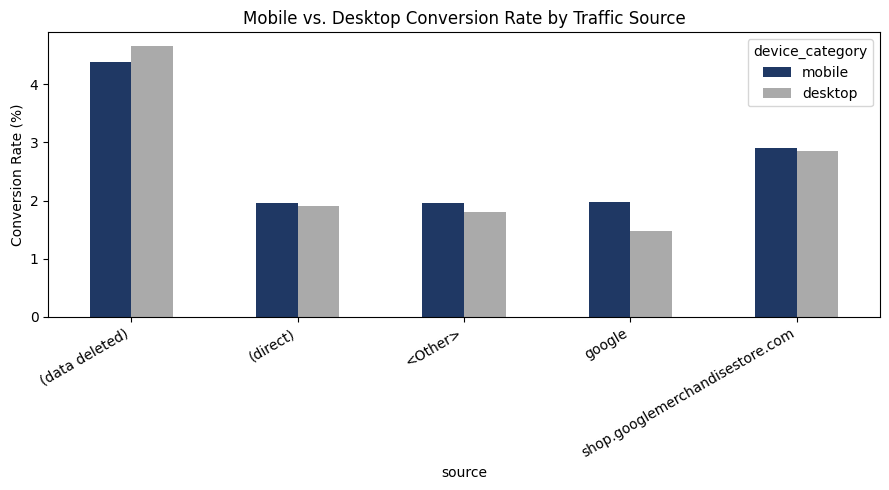

In [17]:
plt.figure(figsize=(9,5))
pivot[['mobile', 'desktop']].plot(kind='bar', figsize=(9,5), color=['#1F3864', '#AAAAAA'])
plt.title('Mobile vs. Desktop Conversion Rate by Traffic Source')
plt.ylabel('Conversion Rate (%)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('device_by_source.png', dpi=150)
plt.show()

The mobile conversion advantage found in the aggregate analysis holds across most traffic sources, and is most pronounced for Google-sourced traffic (2.0% mobile vs. 1.5% desktop) — suggesting mobile-specific optimization efforts may have the highest ROI when paired with Google-driven acquisition specifically, rather than as a blanket device-level investment.